# SML & BDA Lab Experiment 6
# Title - Explainability using SHAP
## Name - Manan Chahal
## Roll No - 23102C0044

# Initilization

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error, r2_score

import xgboost as xgb
import shap

sns.set(style="whitegrid")
shap.initjs()

In [ ]:
df = pd.read_csv('/content/loan_approval_dataset.csv')

In [ ]:
print("Rows, cols:", df.shape)
display(df.head())
print("\nData types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())

Rows, cols: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected



Data types:
loan_id                       int64
 no_of_dependents             int64
 education                   object
 self_employed               object
 income_annum                 int64
 loan_amount                  int64
 loan_term                    int64
 cibil_score                  int64
 residential_assets_value     int64
 commercial_assets_value      int64
 luxury_assets_value          int64
 bank_asset_value             int64
 loan_status                 object
dtype: object

Missing values per column:
loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64


# Preprocessing

In [ ]:
target_col = " loan_status"
print("Using target column:", target_col)

# If target is string, make sure it's categorical
y = df[target_col]
X = df.drop(columns=[target_col])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Using target column:  loan_status
Train shape: (3415, 12) Test shape: (854, 12)


In [ ]:

numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric cols:", numeric_cols)
print("Categorical cols:", cat_cols)


numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="__missing__")),
    ("ohe", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, cat_cols)
], remainder="drop")

Numeric cols: ['loan_id', ' no_of_dependents', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value']
Categorical cols: [' education', ' self_employed']


# Training the XGBoost Model

In [ ]:
# Apply preprocessing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


feature_names = numeric_cols

# Get feature names after preprocessing
preprocessor_feature_names = preprocessor.get_feature_names_out()

# Create DataFrames with processed data and feature names
X_train_processed_df = pd.DataFrame(X_train_processed, columns=preprocessor_feature_names)
X_test_processed_df = pd.DataFrame(X_test_processed, columns=preprocessor_feature_names)

# Map target variable (y_train, y_test) to numerical values if it's not already
y_train_encoded = y_train.map({' Rejected': 0, ' Approved': 1})
y_test_encoded = y_test.map({' Rejected': 0, ' Approved': 1})

# Train XGBoost Model
model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False, random_state=42)
model.fit(X_train_processed_df, y_train_encoded)

print("XGBoost model trained successfully!")

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [06:30:35] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost model trained successfully!


In [ ]:
# Evaluate Model
y_pred = model.predict(X_test_processed_df)
y_pred_proba = model.predict_proba(X_test_processed_df)[:, 1]

accuracy = accuracy_score(y_test_encoded, y_pred)
report = classification_report(y_test_encoded, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("Classification Report:\n", report)

Accuracy: 0.9824
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.97      0.98       323
           1       0.98      0.99      0.99       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



# SHAP Plots

In [ ]:
# Initialize JS for SHAP plots (already done at the beginning, but good to ensure)
shap.initjs()

# Explain the model's predictions using SHAP
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_processed_df)

print("SHAP values calculated.")

SHAP values calculated.


Generating SHAP Bar Plot - Feature Importance...


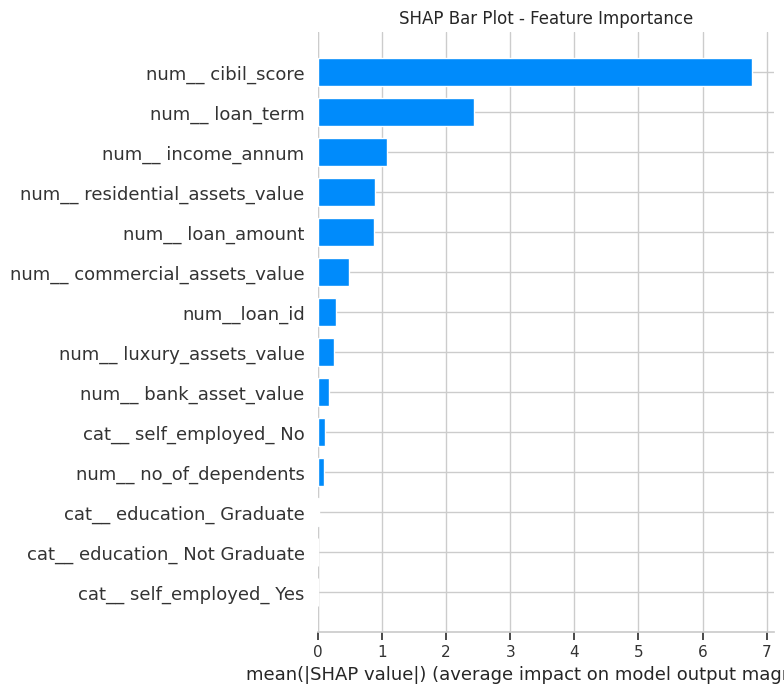

In [ ]:
print("Generating SHAP Bar Plot - Feature Importance...")
plt.title("SHAP Bar Plot - Feature Importance")
shap.summary_plot(shap_values, X_test_processed_df, plot_type="bar")

#plt.show()

Generating SHAP Summary Plot - Feature Impact...


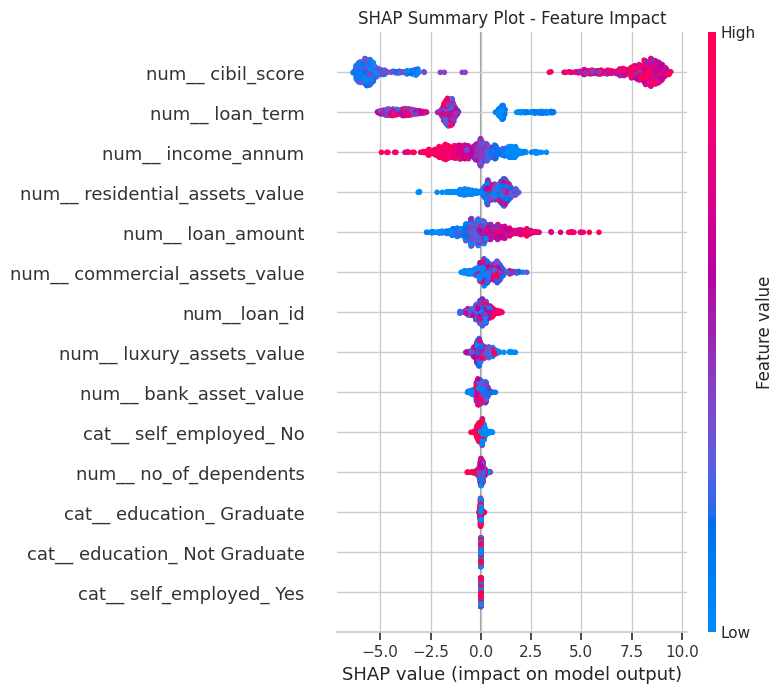

In [ ]:
print("Generating SHAP Summary Plot - Feature Impact...")
plt.title("SHAP Summary Plot - Feature Impact")
shap.summary_plot(shap_values, X_test_processed_df)

